**About Project:**
Capital bike-sharing system is a new-generation bike rental system in which membership, rental, and return are automated. The efficient management of bicycle availability across docking stations across a city is very important to maintain bike demand and reduce operating costs. The Capital Bikeshare system in Washington, D.C., serves thousands of trips daily, and its operational efficiency depends on accurately anticipating bike demand.

We will use a **supervised learning model** to predict target features and an **unsupervised learning model** to discover the usage pattern and clustering.

**About Dataset**:
I am picking a dataset from the UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset). The dataset captures hourly bike rental activity from the Capital Bikeshare system in Washington, D.C., for the years 2011 and 2012. It contains 17,379 hourly records with 17 features covering temporal, environmental, and user-type information.

hour.csv.csv has hourly data, and day.csv has day level data.

Target "cnt": count of total rental bikes including both casual and registered.

In [279]:
# Importing all the libraries
import pandas as pd
import random as rnd
import numpy as np
import seaborn as sns
import logging
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, roc_curve, auc,
    classification_report, confusion_matrix, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, fowlkes_mallows_score
from sklearn.decomposition import PCA


from sklearn import set_config

set_config(display='text')
pd.set_option('display.max_columns',50) # setting up the dataframe display columns
pd.set_option('display.max_colwidth', 200) # setting up column width 100
pd.set_option('display.expand_frame_repr', False)

### Loading data file

I downloaded and copied day.csv and hour.csv file from UCI Machine Learning Repository

In [280]:
file_day = 'day.csv' # file is saved in current directory.

# Catch any exception reading file
try:
    df_day = pd.read_csv(f"{file_day}", sep = ",")
except FileNotFoundError as e: # if file is not not found. 
    logging.error(f"{file_day} is not found, please check the file path or name.\n{e}")

In [281]:
file_hour = 'hour.csv'  # file is saved in current directory.

# Catch any exception reading file
try:
    df_hour = pd.read_csv(f"{file_hour}", sep = ",")
except FileNotFoundError as e: # if file is not not found. 
    logging.error(f"{file_hour} is not found, please check the file path or name.\n{e}")

In [282]:
df_day.head() # day file

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [283]:
df_hour.head() # hour file

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Exploratory Data Analysis (EDA)

Analyzing, data cleaning, and visualizing datasets and identifying underlying patterns of the data.

In [284]:
df_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


I do find any NaN values.

In [285]:
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


I do find any NaN values.

In [286]:
# Checking any duplicate
df_day.duplicated().sum() 

np.int64(0)

In [287]:
df_hour.duplicated().sum() 

np.int64(0)

No duplicate values in both datasets, and zero missing values in both dataframes, so no imputation needed.

**I am going to check and verify that day dataset is derived from hour dataset.**

In [288]:
one_date = '2011-01-02'

# Sum that date's hourly rentals
hour_total = df_hour[df_hour['dteday'] == one_date]['cnt'].sum()

# Look up the same date in the day dataset
day_total = df_day[df_day['dteday'] == one_date]['cnt'].values[0]

print("Sum of df_hour cnt for", one_date, "=", hour_total)
print("df_day cnt for        ", one_date, "=", day_total)

Sum of df_hour cnt for 2011-01-02 = 801
df_day cnt for         2011-01-02 = 801


df_day = df_hour grouped by date and summed/averaged. They are NOT independent datasets, df_day is fully derivable from df_hour. Combining them would just duplicate information. 

**So I will consider only hours.csv dataset for meachine learning models.**

In [289]:
# Convert dteday to datetime — both dataframes

df_day['dteday']  = pd.to_datetime(df_day['dteday'])
df_hour['dteday'] = pd.to_datetime(df_hour['dteday'])


print(df_day['dteday'].dtype)
print(df_hour['dteday'].dtype)

datetime64[ns]
datetime64[ns]


In [290]:
# 1=Winter, 2=Spring, 3=Summer, 4=Fall
season_map = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}

df_day['season_name']  = df_day['season'].map(season_map)
df_hour['season_name'] = df_hour['season'].map(season_map)


In [291]:
df_hr = df_hour.copy()

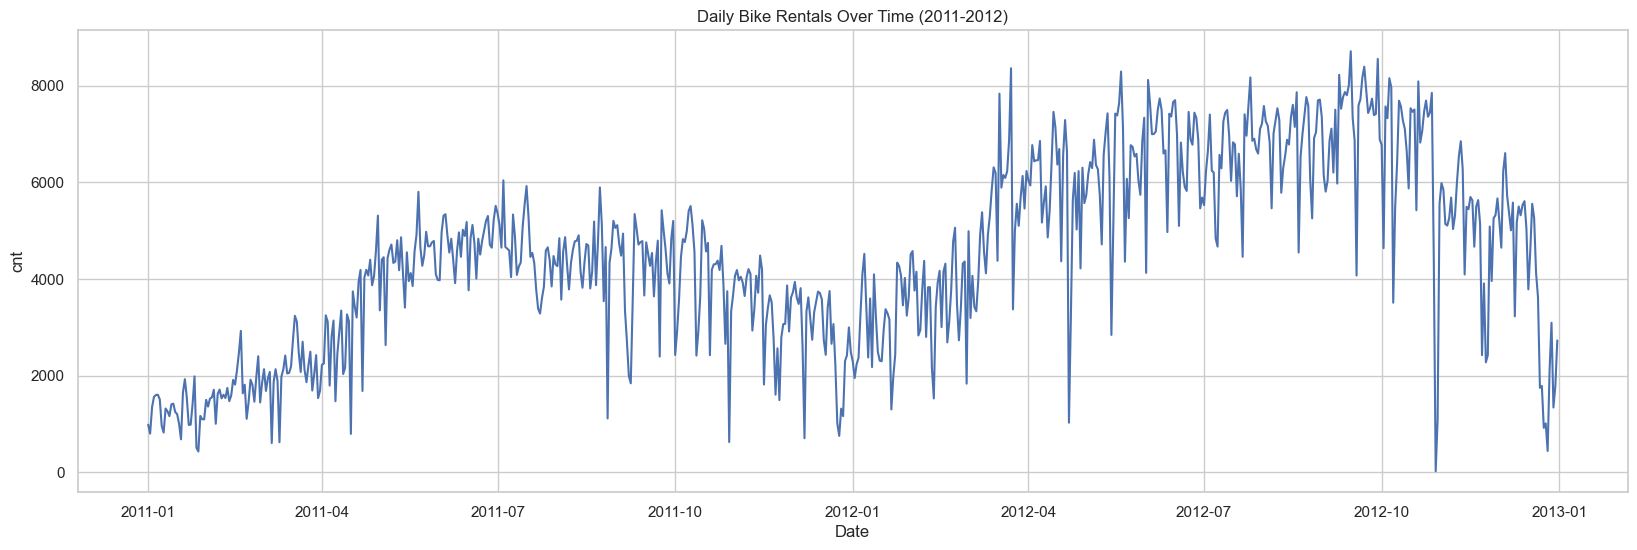

In [292]:
# Daily Bike Rentals Over Time 2011-2012
plt.figure(figsize=(20, 6))
plt.plot(df_day['dteday'], df_day['cnt'])
plt.title('Daily Bike Rentals Over Time (2011-2012)')
plt.xlabel('Date')
plt.ylabel('cnt')
plt.show()

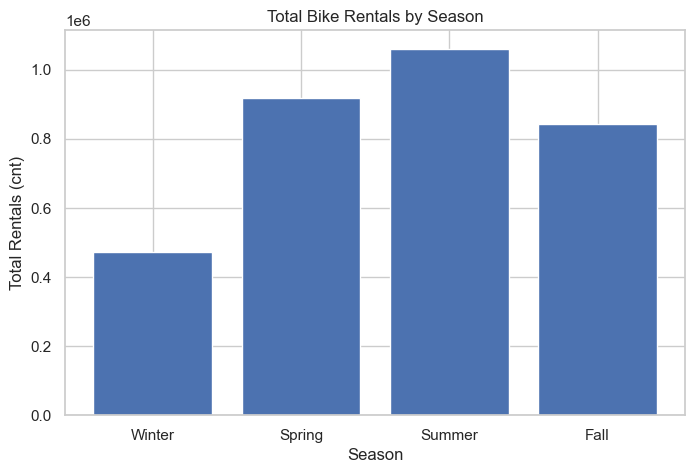

In [293]:
# Total Bike Rentals By Season
season_totals = df_day.groupby('season_name')['cnt'].sum().reindex(['Winter', 'Spring', 'Summer', 'Fall'])

plt.figure(figsize=(8, 5))
plt.bar(season_totals.index, season_totals.values)
plt.title('Total Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Total Rentals (cnt)')
plt.show()

#### Statistical significance - One-Way ANOVA test

In [294]:
# Creating a day_type column (Weekday / Weekend / Holiday
def classify_day(row):
    if row['holiday'] == 1:
        return 'Holiday'
    elif row['weekday'] in [0, 6]:  # 0=Sunday, 6=Saturday
        return 'Weekend'
    else:
        return 'Weekday'

df_day['day_type'] = df_day.apply(classify_day, axis=1)

print(df_day['day_type'].value_counts())

day_type
Weekday    500
Weekend    210
Holiday     21
Name: count, dtype: int64


In [295]:
from scipy.stats import f_oneway

weekday_cnt = df_day[df_day['day_type'] == 'Weekday']['cnt']
weekend_cnt = df_day[df_day['day_type'] == 'Weekend']['cnt']
holiday_cnt = df_day[df_day['day_type'] == 'Holiday']['cnt']

f_stat, p_value = f_oneway(weekday_cnt, weekend_cnt, holiday_cnt)

print(f"F-statistic: {f_stat:.3f}")
print(f"p-value: {p_value:.5f}")
print("Statistically significant?", "Yes" if p_value < 0.05 else "No")

F-statistic: 2.465
p-value: 0.08570
Statistically significant? No


Null hypothesis (H₀): There is no real difference in average rental demand between Weekday, Weekend, and Holiday groups, any differences observed are just random noise.

Alternative hypothesis (H₁): "At least one of these groups has a genuinely different average demand from the others.

p-value (0.0857) >= 0.05, we fail to reject the null hypothesis. We do not have enough evidence that there is a real difference in demand between weekday, weekend, and holiday.

In [296]:
# Descriptive statistics for numeric columns
print("Descriptive statistics:")

# df_hour.select_dtypes(include='number').describe()
df_hr.describe()

Descriptive statistics:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


cnt is right-skewed (mean 189.5 > median 142).

atemp tracks temp almost exactly (means 0.497 vs 0.476), we can drop  atemp as redundant.

registered riders (mean 153.8) outnumber casual riders (mean 35.7).

holiday is true for only ~2.9% of hours, that is expected as holidays are less in a year.

#### IQR statistics: Outliers analysis based on data summary statistics 


Q1 = 0.25 and Q3 = 0.75
IQR Outlier Summary:
                 Q1        Q3       IQR  Lower Bound  Upper Bound  Outlier Count  Outlier %
temp        0.3400    0.6600    0.3200     -0.14000      1.14000            0.0       0.00
atemp       0.3333    0.6212    0.2879     -0.09855      1.05305            0.0       0.00
hum         0.4800    0.7800    0.3000      0.03000      1.23000           22.0       0.13
windspeed   0.1045    0.2537    0.1492     -0.11930      0.47750          342.0       1.97
cnt        40.0000  281.0000  241.0000   -321.50000    642.50000          505.0       2.91


***** Boxplots *****


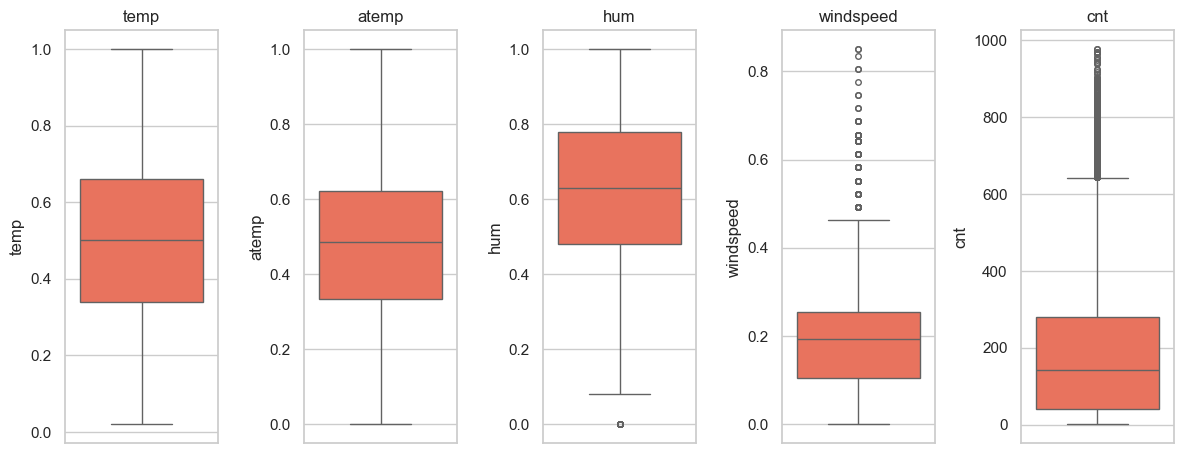

In [297]:
# Candidate numeric columns for df_hr (excludes leakage cols, instant, dteday)
numeric_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']

lower_limit = 0.25
upper_limit = 0.75

def detect_outliers_iqr(data, column, lower_limit, upper_limit):
    Q1 = data[column].quantile(lower_limit)
    Q3 = data[column].quantile(upper_limit)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return Q1, Q3, IQR, lower_bound, upper_bound, outliers

# store results
iqr_results = {}
for col in numeric_cols:
    Q1, Q3, IQR, lower, upper, outliers = detect_outliers_iqr(df_hour, col, lower_limit, upper_limit)
    iqr_results[col] = {'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
                         'Lower Bound': lower, 'Upper Bound': upper,
                         'Outlier Count': len(outliers),
                         'Outlier %': round(len(outliers) / len(df_hour) * 100, 2)}

# dataframe with IQR summary
iqr_df = pd.DataFrame(iqr_results).T
print(f"\nQ1 = {lower_limit} and Q3 = {upper_limit}\nIQR Outlier Summary:\n", iqr_df)


print("\n\n***** Boxplots *****")
plt.figure(figsize=(12, 9))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 5, i)
    sns.boxplot(y=df_hour[col], color='tomato', fliersize=4)
    plt.title(f'{col}')
plt.tight_layout()
plt.show()

**I left out season, yr, mnth, hr, holiday, weekday, workingday, weathersit because those are categorical/binary codes (1, 2, 3, 4 or 0/1), not true continuous measurements .**

IQR outlier detection does not make sense on a column that only takes a few discrete values (e.g., "season" can not have an "outlier" if it only ranges 1–4). I also excluded casual/registered/instant since those are not going into models. I am using "cnt" as target here.

I do not find any significant outliers, so no outliers are removed. High cnt values are important for accurately predicting bike demand on very busy days.

#### Histogram cnt and windspeed

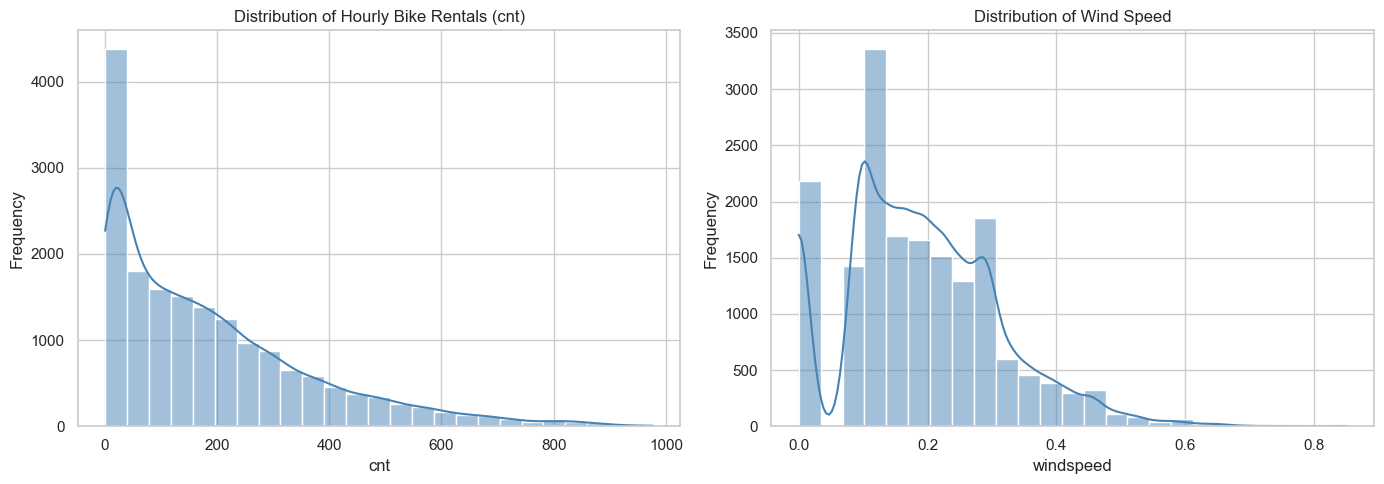

In [298]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of cnt
sns.histplot(df_hour['cnt'], bins=25, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Hourly Bike Rentals (cnt)')
axes[0].set_xlabel('cnt')
axes[0].set_ylabel('Frequency')

# Distribution of windspeed
sns.histplot(df_hour['windspeed'], bins=25, kde=True, color='steelblue', ax=axes[1])
axes[1].set_title('Distribution of Wind Speed')
axes[1].set_xlabel('windspeed')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

cnt is right-skewed, most hours have low rental counts (peak near 0–50), with a long tail stretching to 900+. 

windspeed is also right-skewed but more multi-modal, a dip near 0.05, then a strong peak around 0.10–0.15. The dip suggests very-low-wind hours are actually less common than moderate-wind hours.

In [299]:
df_hr[numeric_cols].skew()

temp        -0.006021
atemp       -0.090429
hum         -0.111287
windspeed    0.574905
cnt          1.277412
dtype: float64

I do see high skew for cnt, comparing log and square root transformation on cnt.

In [300]:
# checking the skewness
from scipy.stats import skew

print("cnt Skewness:")
print("Skewness before:", skew(df_hr['cnt']))
print("Skewness with log1p: ", skew(np.log1p(df_hr['cnt'])))
print("Skewness with sqrt:", skew(np.sqrt(df_hr['cnt'])))



cnt Skewness:
Skewness before: 1.277301346349497
Skewness with log1p:  -0.8181097547310336
Skewness with sqrt: 0.2864498864837601


**sqrt brought "cnt" skewness from 1.28 down to 0.29. I will apply square root transform for K-Means, not log transformation.**

In [301]:
# square root transformation
df_hr['cnt_sqrt'] = np.sqrt(df_hr['cnt'])

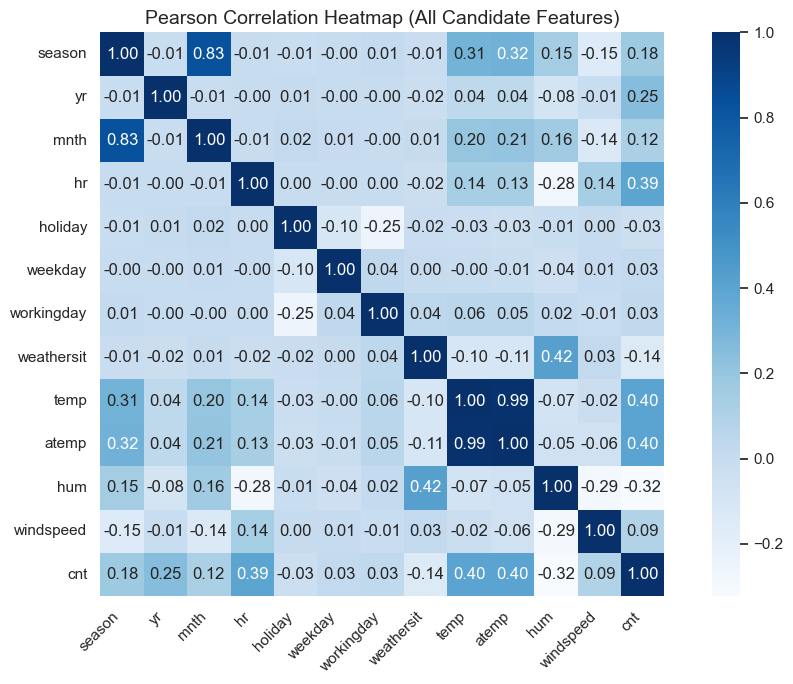

In [302]:
# All real candidate features + target, excluding leakage and instant/dteday
numeric_cols = ['season', 'yr', 'mnth', 'hr', 'holiday',
                'weekday', 'workingday', 'weathersit',
                'temp', 'atemp', 'hum', 'windspeed', 'cnt']

corr_matrix = df_hour[numeric_cols].corr(method='pearson')

# Plot heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", cbar=True, square=True)
plt.title("Pearson Correlation Heatmap (All Candidate Features)", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

temp and atemp have high multicollinearity 0.99 , I will consider temp in feature list, and dropping atemp from the input feature list.

season and month also have a quite high multicollinearity = 0.83. I will keep the month in the input feature list and dropping the season.

### Model Preparation

#### Creating demand_level feature

In [303]:
# quartile cutoffs from cnt
q1 = df_hr['cnt'].quantile(0.25)
q2 = df_hr['cnt'].quantile(0.50)  # median
q3 = df_hr['cnt'].quantile(0.75)

print(f"Q1 (25%): {q1}")
print(f"Q2 (50%, median): {q2}")
print(f"Q3 (75%): {q3}")


Q1 (25%): 40.0
Q2 (50%, median): 142.0
Q3 (75%): 281.0


In [304]:
# demand_level using pd.cut()
demand_bins   = [-1, q1, q2, q3, df_hr['cnt'].max()]
demand_lvl_labels = ['Low', 'Medium', 'High', 'Very High']

df_hr['demand_level'] = pd.cut(df_hr['cnt'], bins=demand_bins, labels=demand_lvl_labels)

In [305]:
# Verify class balance

print("Row counts per class:")
print(df_hr['demand_level'].value_counts())

print("\nPercentage per class:")
print((df_hr['demand_level'].value_counts(normalize=True) * 100).round(2))

Row counts per class:
demand_level
Low          4377
High         4345
Medium       4331
Very High    4326
Name: count, dtype: int64

Percentage per class:
demand_level
Low          25.19
High         25.00
Medium       24.92
Very High    24.89
Name: proportion, dtype: float64


In [327]:
df_hr.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_name,cnt_sqrt,demand_level
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,Winter,4.000000,Low
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,Winter,6.324555,Low
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,Winter,5.656854,Low
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,Winter,3.605551,Low
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,Winter,1.000000,Low


### Model 01- Random Forest Regressor - predicts cnt

In [306]:
# Feature list - no one-hot needed — RF splits on raw integer codes
rf_features = ['mnth', 'yr', 'hr', 'holiday', 'weekday',
               'workingday', 'weathersit', 'temp', 'hum', 'windspeed']

X_reg = df_hr[rf_features].copy()
y_reg = df_hr['cnt'].copy()

# Train and test split - no stratify, it is a continuous target
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
                                                X_reg, y_reg, 
                                                test_size=0.2, 
                                                random_state=42
                                                )

In [307]:
# Pipeline - no preprocessing needed, RF doesn't need scaling.
rf_reg_pipe = Pipeline([
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1))
])

# Hyperparameter search - Search Space Random Forest
rf_reg_param_grid = {
                'model__n_estimators': [10,50,10], # Number of trees
                'model__max_depth': [10, 15, 20],  # How deep each tree goes
                'model__min_samples_split': [2, 5] # Minimum data points to make a split
                }

# Creating grid search- Random Forest
rf_reg_grid = GridSearchCV(
                            rf_reg_pipe,
                            rf_reg_param_grid, cv=5,
                            scoring='neg_root_mean_squared_error', n_jobs=-1
                            )


In [308]:
# Fitting grid search- Random Forest
rf_reg_grid.fit(X_train_reg, y_train_reg)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('model',
                                        RandomForestRegressor(n_jobs=-1,
                                                              random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [10, 15, 20],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [10, 50, 10]},
             scoring='neg_root_mean_squared_error')

In [309]:
print(f"Model Ensemble Random Forest Regressor:")
print(f"\nBest Hyperparameters: {rf_reg_grid.best_params_}")
print(f"Best CV RMSE: {-rf_reg_grid.best_score_:.2f}")
 
# predicting test value- Random Forest
y_pred_reg = rf_reg_grid.predict(X_test_reg)
 
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
mae = mean_absolute_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)
 
print(f"\nTest Set Performance:")
print(f"  RMSE: {rmse:.2f}")
print(f"  MAE:  {mae:.2f}")
print(f"  R²:   {r2:.4f}")

Model Ensemble Random Forest Regressor:

Best Hyperparameters: {'model__max_depth': 20, 'model__min_samples_split': 2, 'model__n_estimators': 50}
Best CV RMSE: 46.30

Test Set Performance:
  RMSE: 43.29
  MAE:  25.59
  R²:   0.9408


**RMSE** = 43.29 : The predicted bike demand is typically off by about 43 rentals.

**MAE** = 25.27 : On average, predictions differ from the actual bike demand by about 25 rentals.

**R²** = 0.9408 : The model explains approximately 94.08% of the variability in bike demand (cnt).

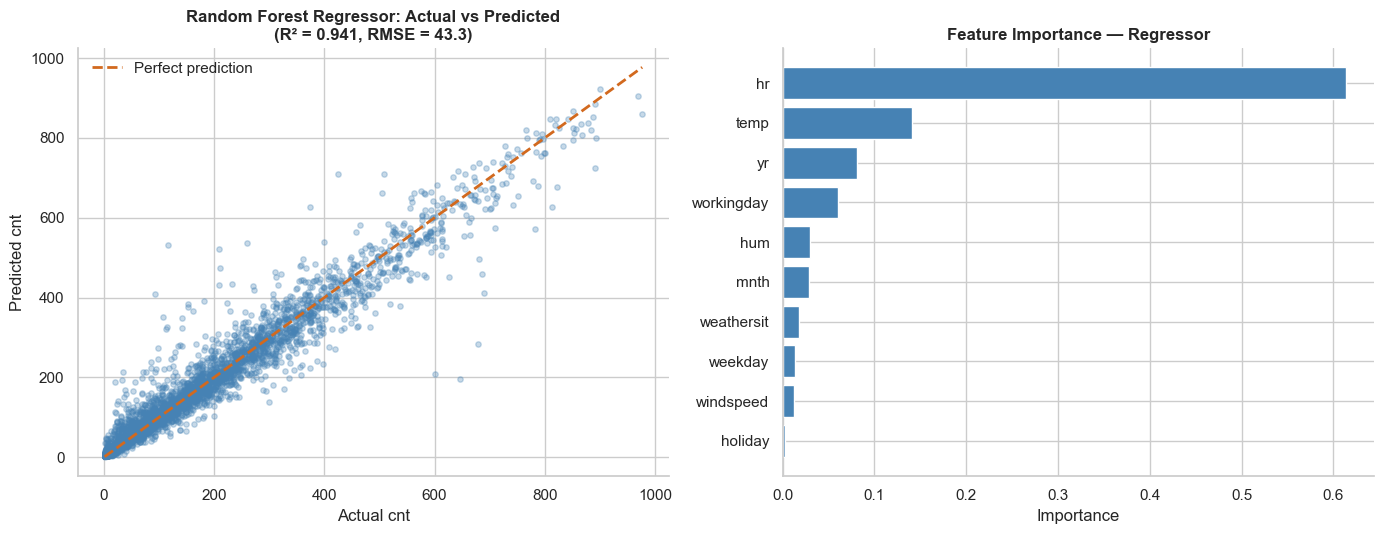

In [310]:
# Visualization- Actual vs Predicted and Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
 
# Actual vs Predicted scatter
axes[0].scatter(y_test_reg, y_pred_reg, alpha=0.3, color='steelblue', s=15)
axes[0].plot([y_test_reg.min(), y_test_reg.max()],
             [y_test_reg.min(), y_test_reg.max()],
             color='chocolate', linestyle='--', linewidth=2, label='Perfect prediction')
axes[0].set_xlabel('Actual cnt')
axes[0].set_ylabel('Predicted cnt')
axes[0].set_title(f'Random Forest Regressor: Actual vs Predicted\n(R² = {r2:.3f}, RMSE = {rmse:.1f})',
                   fontweight='bold')
axes[0].legend(frameon=False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
 
# Feature importance
best_reg_model = rf_reg_grid.best_estimator_.named_steps['model']
reg_importance_df = pd.DataFrame({
    'Feature': rf_features,
    'Importance': best_reg_model.feature_importances_
}).sort_values('Importance', ascending=True)
 
axes[1].barh(reg_importance_df['Feature'], reg_importance_df['Importance'],
             color='steelblue', edgecolor='white')
axes[1].set_xlabel('Importance')
axes[1].set_title('Feature Importance — Regressor', fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
 
plt.tight_layout()
plt.show()


In [311]:
print("\nTop 5 most important features (Regressor):")
print(reg_importance_df.sort_values('Importance', ascending=False).head(5).to_string(index=False))


Top 5 most important features (Regressor):
   Feature  Importance
        hr    0.613608
      temp    0.141064
        yr    0.080689
workingday    0.060252
       hum    0.029511


**hr** (Hour of day) is the most important features with an importance score of 0.61. Model relies on time-of-day more than anything else to predict rentals. 

**temp** (Temperature) is the second strongest predictor (0.14). It confirms the positive relationship between warmer conditions and higher demand.

**yr** (Year) ranks third (0.08), it captures the systematic growth in ridership from 2011 to 2012

workingday (0.06) and humidity (0.03) are also in the top five, explaining that commute patterns and weather conditions jointly preditcs demand.

### Model 02 - Random Forest Classifier - predicts demand_level

In [312]:
# Same features as regressor, different target
X_clf = df_hr[rf_features].copy()
y_clf = df_hr['demand_level'].copy()
 
# Train and test split with stratify - preserve class balance
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
                                                X_clf, y_clf, 
                                                test_size=0.2, 
                                                random_state=42, 
                                                stratify=y_clf
                                                )

In [313]:
# Pipeline 
rf_clf_pipe = Pipeline([
    ('model', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Hyperparameter search - Search Space Random Forest
rf_clf_param_grid = {
                    'model__n_estimators': [10,50,10], # Number of trees
                    'model__max_depth': [10, 15, 20],  # How deep each tree goes
                    'model__min_samples_split': [2, 5] # Minimum data points to make a split
                    }

# scoring='f1_macro' treats all 4 classes equally, it is appropriate since classes are balanced.
rf_clf_grid = GridSearchCV( rf_clf_pipe, 
                            rf_clf_param_grid, 
                            cv=5,
                            scoring='f1_macro', n_jobs=-1
                          )

In [314]:
# Fitting the model
rf_clf_grid.fit(X_train_clf, y_train_clf)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('model',
                                        RandomForestClassifier(n_jobs=-1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [10, 15, 20],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [10, 50, 10]},
             scoring='f1_macro')

In [335]:
print(f"Model Ensemble Random Forest Classifer:")
print(f"\nBest Hyperparameters: {rf_clf_grid.best_params_}")
print(f"Best CV F1 (macro): {rf_clf_grid.best_score_:.2%}")

Model Ensemble Random Forest Classifer:

Best Hyperparameters: {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 50}
Best CV F1 (macro): 82.73%



Test Accuracy: 84.26%

Classification Report:
              precision    recall  f1-score   support

        High       0.76      0.76      0.76       869
         Low       0.94      0.93      0.93       876
      Medium       0.79      0.79      0.79       866
   Very High       0.89      0.89      0.89       865

    accuracy                           0.84      3476
   macro avg       0.84      0.84      0.84      3476
weighted avg       0.84      0.84      0.84      3476



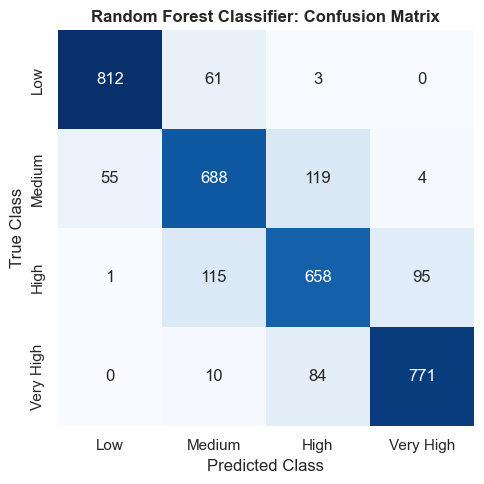

In [336]:
# predicting test value- Random Forest
y_pred_clf = rf_clf_grid.predict(X_test_clf)
 
print(f"\nTest Accuracy: {accuracy_score(y_test_clf, y_pred_clf):.2%}")
print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_clf))
 
# Confusion Matrix heatmap 
class_order = ['Low', 'Medium', 'High', 'Very High']
conf_matrix = confusion_matrix(y_test_clf, y_pred_clf, labels=class_order)
conf_df = pd.DataFrame(conf_matrix, index=class_order, columns=class_order)
 
plt.figure(figsize=(5, 5))
sns.heatmap(conf_df, annot=True, fmt='d', cbar=False, cmap='Blues')
plt.title('Random Forest Classifier: Confusion Matrix', fontweight='bold')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

The Random Forest Classifier achieved 84.3% overall accuracy across four demand categories, It is above the 25% random-guessing baseline for a balanced four-class problem.

Low demand was predicted most reliably (F1 = 0.93) and Very High second (F1 = 0.89), we can easily identify both extreme classes.

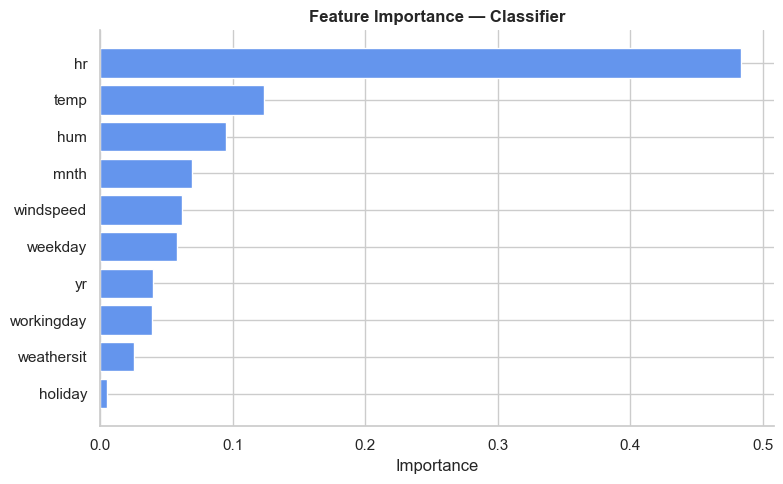


Top 5 most important features (Classifier):
  Feature  Importance
       hr    0.484111
     temp    0.123502
      hum    0.095113
     mnth    0.068920
windspeed    0.061774


In [318]:
# Feature importance 
best_clf_model = rf_clf_grid.best_estimator_.named_steps['model']
clf_importance_df = pd.DataFrame({
    'Feature': rf_features,
    'Importance': best_clf_model.feature_importances_
}).sort_values('Importance', ascending=False)
 
plt.figure(figsize=(8, 5))
plt.barh(clf_importance_df['Feature'][::-1], clf_importance_df['Importance'][::-1],
          color='cornflowerblue', edgecolor='white')
plt.xlabel('Importance')
plt.title('Feature Importance — Classifier', fontweight='bold')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.show()
 
print("\nTop 5 most important features (Classifier):")
print(clf_importance_df.head(5).to_string(index=False))

**hr** (Hour of day) is the most important features with an importance score of 0.48.


### Model 03- K-Means Clustering - uunsupervised usage pattern discovery

In [329]:
# Feature list —  includes cnt_sqrt , cnt feature transformed using Square Root tranformation
km_numeric_features  = ['hr', 'mnth', 'weekday', 'temp', 'hum', 'windspeed', 'cnt_sqrt']
km_categorical_features = ['holiday', 'workingday', 'weathersit']  # one-hot for K-Means

km_features = km_numeric_features + km_categorical_features

X_km_raw = df_hr[km_features].copy()


In [320]:
# Preprocessing pipeline: scale numeric, one-hot categorical
km_preprocessor = ColumnTransformer(
    transformers=[
        ('scale', StandardScaler(), km_numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'),
         km_categorical_features)
    ]
)
 
X_km_scaled = km_preprocessor.fit_transform(X_km_raw)
print(f"Scaled feature matrix shape: {X_km_scaled.shape}")

Scaled feature matrix shape: (17379, 12)


In [333]:
print("Number of features in K-Means:", X_km_scaled.shape[1])

Number of features in K-Means: 12


k=2: Inertia=105312, Silhouette Score=0.1857
k=3: Inertia=91909, Silhouette Score=0.1855
k=4: Inertia=84221, Silhouette Score=0.1629
k=5: Inertia=79054, Silhouette Score=0.1616
k=6: Inertia=74537, Silhouette Score=0.1517
k=7: Inertia=71287, Silhouette Score=0.1421


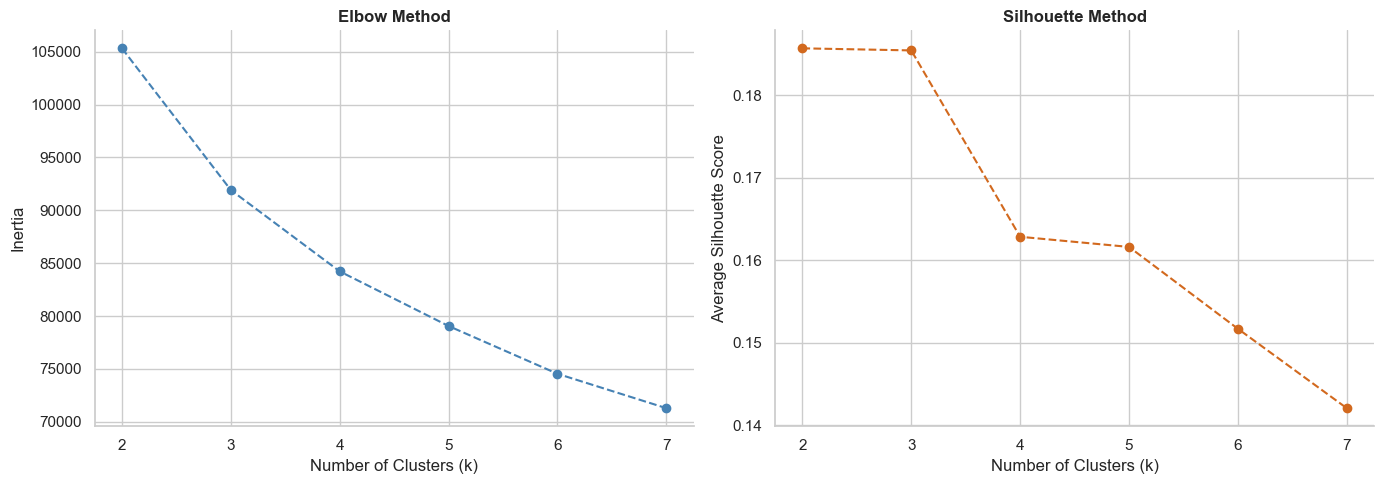

In [321]:
#  Elbow and Silhouette analysis to choose k  
k_range = range(2, 8)
inertias = []
sil_scores = []
 
for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(X_km_scaled)
    inertias.append(kmeans_temp.inertia_)
    score = silhouette_score(X_km_scaled, labels_temp)
    sil_scores.append(score)
    print(f"k={k}: Inertia={kmeans_temp.inertia_:.0f}, Silhouette Score={score:.4f}")
 
# Elbow and Silhouette plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
axes[0].plot(k_range, inertias, marker='o', linestyle='--', color='steelblue')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method', fontweight='bold')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
 
axes[1].plot(k_range, sil_scores, marker='o', linestyle='--', color='chocolate')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Average Silhouette Score')
axes[1].set_title('Silhouette Method', fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
 
plt.tight_layout()
plt.show()

Silhouette coefficient is used to measure the quality of the clusters.

The value returned by the silhouette_score is the mean silhouette coefficient for all observations, with a silhouette coefficient range between -1 and 1, with 1 indicating dense, well-separated clusters.

Here, clusters = 2 has the highest positive values, so I will pick cluster = 2.

In [322]:
#  Fit final K-Means with chosen k  
optimal_k = 2
 
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_km_scaled)
 
print(f"\nCluster sizes (k={optimal_k}):")
print(pd.Series(cluster_labels).value_counts().sort_index())



Cluster sizes (k=2):
0     7362
1    10017
Name: count, dtype: int64



Variance explained by 2 PCA components: 45.17%


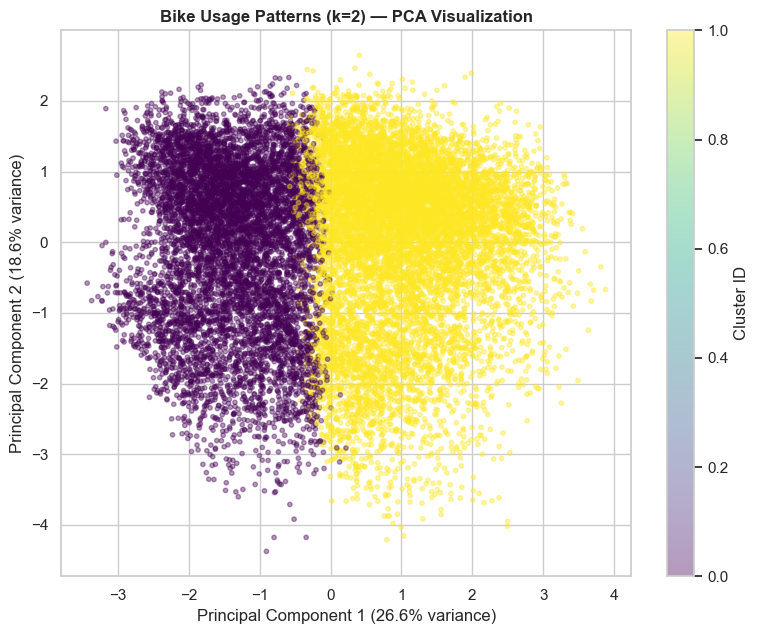

In [323]:
# PCA visualization of clusters 
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_km_scaled)
print(f"\nVariance explained by 2 PCA components: {pca.explained_variance_ratio_.sum():.2%}")
 
plt.figure(figsize=(8, 6.5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels,
                       cmap='viridis', alpha=0.4, s=10)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title(f'Bike Usage Patterns (k={optimal_k}) — PCA Visualization', fontweight='bold')
plt.colorbar(scatter, label='Cluster ID')
plt.tight_layout()
plt.show()

The PCA scatter plot compresses all 12 features into 2 dimensions (.PC1 captures 26.6% variance, PC2 captures 18.6%, together 45.2%).

K-Means cluster — purple = Cluster 0 (off-peak/low demand) and yellow = Cluster 1 (active/high demand)

In [324]:
#  Profile for each cluster and what does it represent?  
df_clustered = df_hr.copy()
df_clustered['cluster_label'] = cluster_labels
 
cluster_profile = df_clustered.groupby('cluster_label')[
    ['hr', 'temp', 'hum', 'windspeed', 'cnt', 'workingday']
].mean().round(2)
 
print("\nCluster profiles (mean values per cluster):")
print(cluster_profile)


Cluster profiles (mean values per cluster):
                  hr  temp   hum  windspeed     cnt  workingday
cluster_label                                                  
0               5.66  0.42  0.74       0.16   60.26        0.66
1              15.87  0.55  0.54       0.21  284.42        0.70


Cluster 0 (n=7,362) is the low-demand or off-peak group, it's average hour is 5.66am overnight or early morning or cooler temperatures, and mean rental count is just 60 rentals/hour.

Cluster 1 (n=10,017) is the high-demand or active hours grou, it's average hour is 3:52pm afternoon or commute window, warmer temperatures,and a mean rental count is 284 rentals/hour.

In [325]:
#  Compare clusters against demand_level (Fowlkes-Mallows Index)  
fmi = fowlkes_mallows_score(df_hr['demand_level'], cluster_labels)
print(f"\nFowlkes-Mallows Index (clusters vs. demand_level): {fmi:.4f}")


Fowlkes-Mallows Index (clusters vs. demand_level): 0.5395


The Fowlkes-Mallows score is 0.54, and K-Means independently discovered a meaningful low-vs-high demand labels.

Fowlkes-Mallows Index (FMI) measures how well K-Means clustering results match a known set of labels. FMI explains how much an unsupervised K-Means result agrees with a supervised labeling without K-Means ever having seen those labels.

1.0 = K-Means clusters perfectly match the known labels


In [326]:
# Cross-tab-  clusters align with demand levels?
crosstab = pd.crosstab(df_clustered['cluster_label'], df_clustered['demand_level'])
print("\nCluster vs. Demand Level cross-tabulation:")
print(crosstab)


Cluster vs. Demand Level cross-tabulation:
demand_level    Low  Medium  High  Very High
cluster_label                               
0              4192    2333   653        184
1               185    1998  3692       4142
